# Airline Flight Delay Prediction

**Prepared by:**

| Student Name | Student ID |
|---|---|
| Reem Alwegdani | 2323653 |
| Shahad Banakher | 2305945 |
| Jory Alsufyani | 2306407 |
| Reem Alzahrani | 2307042 |

**Section:** DAR

## Project Overview

This project aims to predict whether an airline flight will arrive on time or experience a delay using historical flight data. The analysis is based on the `flights.csv` dataset, which contains information about flight schedules, airlines, airports, departure and arrival times, and flight distances.

The prediction task is formulated as a binary classification problem. Flights arriving 15 minutes or more after their scheduled arrival time are classified as delayed, while the remaining flights are classified as on time.

The project involves data exploration, preprocessing, feature selection, and the implementation of three classification algorithms: Logistic Regression, Decision Tree, and Random Forest. The models are evaluated using standard classification metrics to compare their ability to identify delayed flights.

To ensure realistic predictions, only features available before departure are considered during model training.

## 1. Dataset Loading

The dataset used in this project is the **US DOT Flight Delays** dataset, obtained from Kaggle. The analysis uses `flights.csv`, which contains historical flight records, including airline information, flight schedules, airport identifiers, and delay details.

Airport identifiers are loaded as strings to ensure consistent data representation during the analysis.

In [1]:
# Libraries and dataset access
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolve the KaggleHub dataset directory
path = kagglehub.dataset_download("usdot/flight-delays")
file_path = os.path.join(path, "flights.csv")

if not os.path.isfile(file_path):
    raise FileNotFoundError("flights.csv is missing from the KaggleHub dataset folder: " + path)

# Preserve airport identifiers as strings
flights = pd.read_csv(
    file_path,
    dtype={"ORIGIN_AIRPORT": "str", "DESTINATION_AIRPORT": "str"},
    low_memory=False
)

print("Flights:", flights.shape)

Flights: (5819079, 31)


## 2. Dataset Inspection

The dataset is examined to understand its structure and contents. The first and last five records are displayed to provide an initial overview, followed by the total number of rows and columns.

In [2]:
# Display the first and last five flights
display(flights.head())
display(flights.tail())

# Display number of rows and columns
print("Number of instances:", flights.shape[0])
print("Number of attributes:", flights.shape[1])

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
5819074,2015,12,31,4,B6,688,N657JB,LAX,BOS,2359,...,753.0,-26.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819075,2015,12,31,4,B6,745,N828JB,JFK,PSE,2359,...,430.0,-16.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819076,2015,12,31,4,B6,1503,N913JB,JFK,SJU,2359,...,432.0,-8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819077,2015,12,31,4,B6,333,N527JB,MCO,SJU,2359,...,330.0,-10.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819078,2015,12,31,4,B6,839,N534JB,JFK,BQN,2359,...,442.0,2.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Number of instances: 5819079
Number of attributes: 31


### 2.1 Missing Values and Duplicate Records

The dataset is checked for missing values and duplicate records to assess data quality. Missing values are identified for each attribute, while duplicate records are examined to detect repeated entries. Some attributes, such as cancellation reasons and delay causes, may contain missing values because they do not apply to all flights.

In [3]:
# Display data types and non-null counts
flights.info()

# Count missing values in each column
print("Missing values per attribute:")
print(flights.isnull().sum())

print("Total missing values:", flights.isnull().sum().sum())
print("Duplicate rows:", flights.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       str    
 8   DESTINATION_AIRPORT  str    
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  CANCELLED

In [4]:
# Check whether missing values use text placeholders
# Only text columns can contain these strings
text_columns = flights.select_dtypes(include=["object", "str"]).columns

for column in text_columns:
    print(column)
    print("Unknown:", (flights[column] == "unknown").sum())
    print("Question mark:", (flights[column] == "?").sum())

AIRLINE
Unknown: 0
Question mark: 0
TAIL_NUMBER
Unknown: 0
Question mark: 0
ORIGIN_AIRPORT
Unknown: 0
Question mark: 0
DESTINATION_AIRPORT
Unknown: 0
Question mark: 0
CANCELLATION_REASON
Unknown: 0
Question mark: 0


### 2.2 Attribute Types and Categories

The data types of each attribute are examined to identify numerical and categorical variables. The distribution of categorical attributes, including airline and airport codes, is also explored to understand the values represented in the dataset.

In [5]:
# Show all data types
print(flights.dtypes)

# Show text-based categorical attributes
print("Text categorical columns:")
print(flights.select_dtypes(include=["object", "str"]).columns.tolist())

# Display categories for selected flight attributes
for column in ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"]:
    print(" ", column)
    print("Number of categories:", flights[column].nunique())
    print(flights[column].value_counts().head(10))

# Numeric-coded categorical attributes
for column in ["MONTH", "DAY_OF_WEEK", "CANCELLED", "DIVERTED"]:
    print(" ", column, ":", sorted(flights[column].dropna().unique()))

YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                    str
FLIGHT_NUMBER            int64
TAIL_NUMBER                str
ORIGIN_AIRPORT             str
DESTINATION_AIRPORT        str
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME         float64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERTED                 int64
CANCELLED                int64
CANCELLATION_REASON        str
AIR_SYSTEM_DELAY       float64
SECURITY_DELAY         float64
AIRLINE_DELAY          float64
LATE_AIRCRAFT_DELAY    float64
WEATHER_DELAY          float64
dtype: object
Text categorical columns:

## 3. Exploratory Data Analysis

The distribution of arrival delays is examined using histograms and boxplots to identify common delay patterns, variability, and outliers. A scatter plot is used to explore the relationship between departure and arrival delays. A random sample is used for the scatter plot to improve readability without modifying the original dataset.

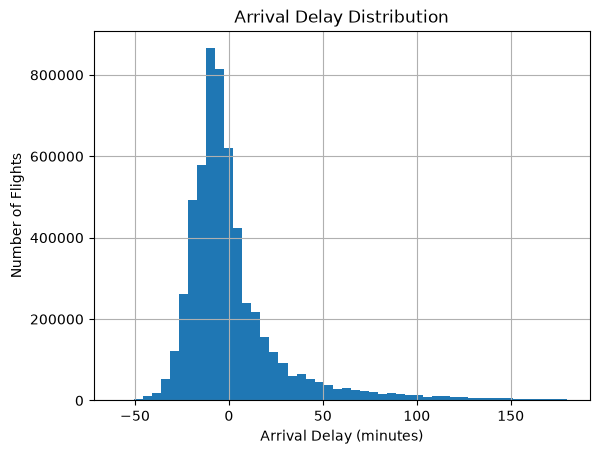

In [6]:
# Histogram: distribution of arrival delay in minutes
flights["ARRIVAL_DELAY"].dropna().hist(bins=50, range=(-60, 180))
plt.title("Arrival Delay Distribution")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.show()

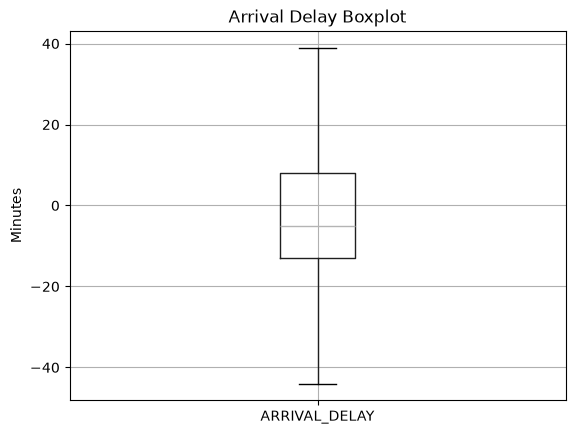

In [7]:
# Boxplot: distribution and spread of arrival delay
# Hide individual outlier points to make the central box easier to see
flights.boxplot(column="ARRIVAL_DELAY", showfliers=False)
plt.title("Arrival Delay Boxplot")
plt.ylabel("Minutes")
plt.show()

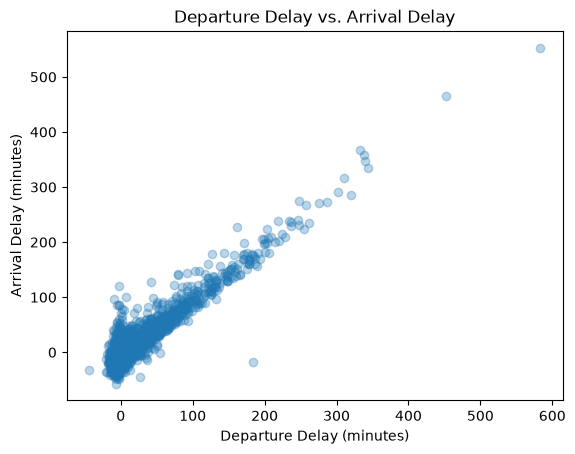

In [8]:
# Scatter plot: departure delay vs. arrival delay
# Sample rows for faster plotting
plot_data = flights[["DEPARTURE_DELAY", "ARRIVAL_DELAY"]].dropna()
plot_data = plot_data.sample(n=min(5000, len(plot_data)), random_state=42)

plt.scatter(plot_data["DEPARTURE_DELAY"], plot_data["ARRIVAL_DELAY"], alpha=0.3)
plt.title("Departure Delay vs. Arrival Delay")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")
plt.show()

### 3.1 Correlation Analysis

Pearson correlation coefficients are calculated to examine the relationships between selected numerical attributes. The results are presented in a correlation heatmap to identify positive and negative relationships. Departure delays and other information recorded after departure are included in this analysis but excluded from model training to avoid data leakage.

                 DEPARTURE_DELAY  ARRIVAL_DELAY  AIR_TIME  DISTANCE  TAXI_OUT  \
DEPARTURE_DELAY            1.000          0.945     0.023     0.024     0.059   
ARRIVAL_DELAY              0.945          1.000    -0.007    -0.025     0.227   
AIR_TIME                   0.023         -0.007     1.000     0.986     0.088   
DISTANCE                   0.024         -0.025     0.986     1.000     0.072   
TAXI_OUT                   0.059          0.227     0.088     0.072     1.000   
TAXI_IN                    0.013          0.117     0.082     0.075     0.003   
SCHEDULED_TIME             0.028         -0.030     0.991     0.984     0.112   

                 TAXI_IN  SCHEDULED_TIME  
DEPARTURE_DELAY    0.013           0.028  
ARRIVAL_DELAY      0.117          -0.030  
AIR_TIME           0.082           0.991  
DISTANCE           0.075           0.984  
TAXI_OUT           0.003           0.112  
TAXI_IN            1.000           0.099  
SCHEDULED_TIME     0.099           1.000  


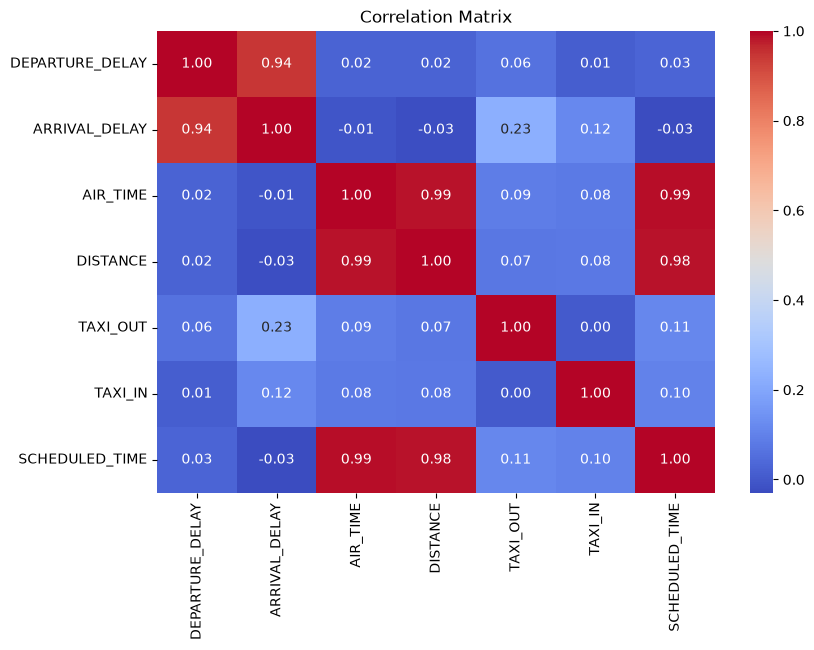

In [9]:
# Select numerical attributes to examine relationships
correlation_columns = [
    "DEPARTURE_DELAY", "ARRIVAL_DELAY", "AIR_TIME",
    "DISTANCE", "TAXI_OUT", "TAXI_IN", "SCHEDULED_TIME"
]

correlation = flights[correlation_columns].corr()
print(correlation.round(3))

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### 3.2 Exploration Summary

The exploratory analysis provides an overview of the dataset's structure, missing values, attribute types, and flight delay patterns. These findings help identify data quality issues and guide the preprocessing and feature selection steps required for model development.

## 4. Data Preprocessing

### 4.1 Target Definition and Record Filtering

Cancelled and diverted flights, as well as records with missing arrival-delay values, are excluded from the analysis. A binary target variable, `DELAYED`, is created to classify flights as delayed (`1`) if they arrive 15 minutes or more after the scheduled arrival time, and on time (`0`) otherwise. The `ARRIVAL_DELAY` attribute is excluded from the predictor variables to prevent data leakage.

In [10]:
# Check records before cleaning
print("Original flights:", len(flights))
print("Cancelled flights:", (flights["CANCELLED"] == 1).sum())
print("Diverted flights:", (flights["DIVERTED"] == 1).sum())
print("Missing arrival delay:", flights["ARRIVAL_DELAY"].isnull().sum())

# Keep completed flights with known arrival delays
flights_clean = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0) &
    (flights["ARRIVAL_DELAY"].notnull())
].copy()

# Remove exact duplicate records, if any
flights_clean = flights_clean.drop_duplicates()

# Create target: 1 = delayed 15 minutes or more
flights_clean["DELAYED"] = (flights_clean["ARRIVAL_DELAY"] >= 15).astype(int)

print("Remaining flights:", len(flights_clean))
print(flights_clean["DELAYED"].value_counts())
print(flights_clean["DELAYED"].value_counts(normalize=True) * 100)

Original flights: 5819079
Cancelled flights: 89884
Diverted flights: 15187
Missing arrival delay: 105071
Remaining flights: 5714008
DELAYED
0    4650569
1    1063439
Name: count, dtype: int64
DELAYED
0    81.388913
1    18.611087
Name: proportion, dtype: float64


### 4.2 Class Distribution

The number and percentage of on-time and delayed flights are calculated to examine the distribution of the target variable. This analysis helps identify class imbalance and guides the selection of appropriate classification techniques and evaluation metrics.

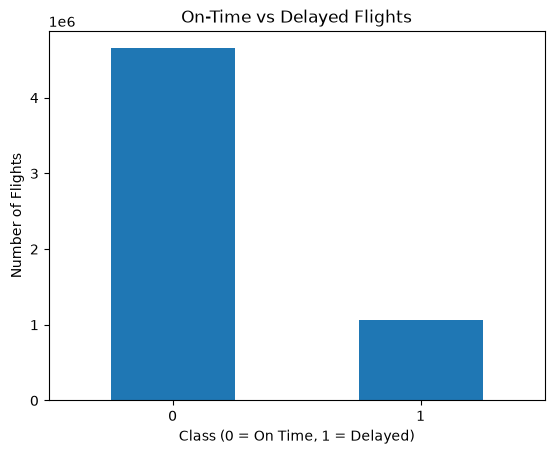

In [11]:
# Show on-time vs delayed flights
flights_clean["DELAYED"].value_counts().sort_index().plot(kind="bar")
plt.title("On-Time vs Delayed Flights")
plt.xlabel("Class (0 = On Time, 1 = Delayed)")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.show()

### 4.3 Feature Selection

Six features are selected for predicting flight delays: month, day of month, day of week, scheduled departure time, scheduled arrival time, and flight distance. Scheduled times are converted from HHMM format into minutes after midnight for numerical processing. Only information available before departure is included, while actual departure and arrival details are excluded to prevent data leakage.

In [12]:
# Choose six scheduled features
features = [
    "MONTH", "DAY", "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE", "SCHEDULED_ARRIVAL", "DISTANCE"
]

X = flights_clean[features].copy()
y = flights_clean["DELAYED"]

# Convert HHMM times to minutes after midnight
X["SCHEDULED_DEPARTURE"] = (X["SCHEDULED_DEPARTURE"] // 100) * 60 + (X["SCHEDULED_DEPARTURE"] % 100)
X["SCHEDULED_ARRIVAL"] = (X["SCHEDULED_ARRIVAL"] // 100) * 60 + (X["SCHEDULED_ARRIVAL"] % 100)

print("Selected features:", X.columns.tolist())
display(X.head())

Selected features: ['MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'SCHEDULED_ARRIVAL', 'DISTANCE']


,MONTH,DAY,DAY_OF_WEEK,SCHEDULED_DEPARTURE,SCHEDULED_ARRIVAL,DISTANCE
0,1,1,4,5,270,1448
1,1,1,4,10,470,2330
2,1,1,4,20,486,2296
3,1,1,4,20,485,2342
4,1,1,4,25,200,1448


### 4.4 Data Splitting

The dataset is divided into training (64%), validation (16%), and testing (20%) sets. Stratified splitting is applied to preserve the proportion of on-time and delayed flights across the three sets. The training set is used to train the model, the validation set to select the classification threshold, and the test set to evaluate the final model's performance on unseen data.

In [13]:
from sklearn.model_selection import train_test_split

# Reserve 20% of the records for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Use 20% of the remaining records for threshold validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20,
    random_state=42, stratify=y_train_val
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

Training records: 3656964
Validation records: 914242
Testing records: 1142802


### 4.5 Missing-Value Handling and Scaling

Missing numerical values are replaced using the median values calculated from the training set. Feature scaling is then applied to standardize the numerical attributes. Both the imputer and scaler are fitted only on the training data and applied to the validation and test sets to prevent data leakage.

In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
X_train_filled = imputer.fit_transform(X_train)
X_val_filled = imputer.transform(X_val)
X_test_filled = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_filled)
X_val_scaled = scaler.transform(X_val_filled)
X_test_scaled = scaler.transform(X_test_filled)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (3656964, 6)
Validation shape: (914242, 6)
Testing shape: (1142802, 6)


## 5. Logistic Regression

### 5.1 Model Training

Logistic Regression is trained to predict whether a flight will arrive on time or be delayed. Since delayed flights represent the minority class, balanced class weights are applied to reduce the model's bias toward on-time predictions. One final Logistic Regression model is used for comparison with the other classification algorithms.

In [15]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=42
)
log_reg.fit(X_train_scaled, y_train)
print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


### 5.2 Classification Threshold Selection

The model's predicted probabilities are evaluated using different classification thresholds on the validation set. The threshold that achieves the highest F1-score is selected to balance precision and recall when identifying delayed flights. The test set is kept separate and used only for final evaluation to avoid biasing the results.

In [16]:
from sklearn.metrics import f1_score

val_probabilities = log_reg.predict_proba(X_val_scaled)[:, 1]
thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []
for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype(int)
    score = f1_score(y_val, val_predictions, zero_division=0)
    threshold_results.append([round(float(threshold), 2), score])

threshold_table = pd.DataFrame(threshold_results, columns=["Threshold", "Validation F1-score"])
display(threshold_table.round(4))

best_row = threshold_table["Validation F1-score"].idxmax()
best_threshold = threshold_table.loc[best_row, "Threshold"]
print("Selected threshold:", best_threshold)
print("Best validation F1-score:", round(threshold_table.loc[best_row, "Validation F1-score"], 4))

,Threshold,Validation F1-score
0,0.20,0.3138
1,0.25,0.3138
2,0.30,0.3145
3,0.35,0.3233
4,0.40,0.3380
5,0.45,0.3466
6,0.50,0.3428
7,0.55,0.3157
8,0.60,0.2386
9,0.65,0.0933


Selected threshold: 0.45
Best validation F1-score: 0.3466


### 5.3 Cross-Validation

Three-fold cross-validation is performed on the training set to assess the consistency of the class-weighted Logistic Regression model. Missing-value imputation and feature scaling are fitted separately within each fold to prevent data leakage. F1-scores are calculated using the default classification threshold of 0.5, while the threshold selected from the validation set is evaluated separately on the held-out test set.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

cv_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ))
])

cv_scores = cross_val_score(cv_model, X_train, y_train, cv=3, scoring="f1")
print("Cross-validation F1-scores:", cv_scores.round(4))
print("Mean F1-score:", round(cv_scores.mean(), 4))

Cross-validation F1-scores: [0.3442 0.344  0.3438]
Mean F1-score: 0.344


## 6. Final Model Evaluation

The classification threshold selected from the validation set is applied to the held-out test set to evaluate the final Logistic Regression model. Performance is measured using accuracy, precision, recall, and F1-score. A confusion matrix is also used to examine correctly classified flights, missed delays, and false-positive predictions. These metrics provide a comprehensive assessment of the model's ability to identify delayed flights.

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.4756,0.226,0.7497,0.3473


Confusion matrix:
[[384056 546058]
 [ 53244 159444]]


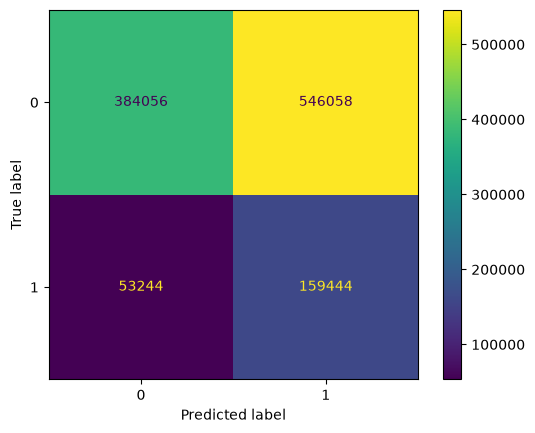

In [18]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# Evaluate the selected model on unseen test records
test_probabilities = log_reg.predict_proba(X_test_scaled)[:, 1]
y_pred = (test_probabilities >= best_threshold).astype(int)

results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, y_pred)],
    "Precision": [precision_score(y_test, y_pred, zero_division=0)],
    "Recall": [recall_score(y_test, y_pred, zero_division=0)],
    "F1-score": [f1_score(y_test, y_pred, zero_division=0)]
})
display(results.round(4))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

## 7. Results and Discussion

The final Logistic Regression model is evaluated using the classification threshold selected from the validation set. Since delayed flights represent the minority class, precision, recall, and F1-score are considered alongside accuracy to assess the model's ability to identify delays while limiting false-positive predictions. The final test results are compared with Decision Tree and Random Forest using the same test set, features, and target definition to ensure a fair comparison.

## 8. Challenges and Limitations

The main challenges include the large dataset size and class imbalance, which can affect processing time and the model's ability to identify delayed flights. The model uses only scheduled flight information, excluding potentially useful features such as airline, airport, route, and weather conditions. Additionally, the random data split does not assess how well the model would perform on flights from future time periods.